In [1]:
ls

accuracy_scalability_3_5_8_10.pdf    class_f1_heatmap.pdf
accuracy_vs_energy_all_labeled.pdf   test_service_10/
accuracy_vs_latency_all_labeled.pdf  test_service_3/
analyser_rq1.ipynb                   test_service_5/
analyser_rq2.ipynb                   test_service_8/
analyser_rq3.ipynb                   vram_peak_summary.csv
Analyser.ipynb                       vram_vs_accuracy_all_labeled.pdf


# RQ1: Model-Level Routing Effectiveness

In [1]:
from pathlib import Path
import pandas as pd

results_folder = Path("test_service_10")

result_files = [
    file
    for file in results_folder.glob("*.csv")
    if file.name != "emissions.csv"
]

print(len(result_files))

20


In [2]:
all_results = []

for file_path in result_files:
    df = pd.read_csv(file_path)
    all_results.append(df)

rq1_df = pd.concat(
    all_results,
    ignore_index=True
)

print(rq1_df.shape)

(22000, 15)


In [3]:
rq1_df.columns

Index(['routing_method', 'query', 'raw_response', 'predicted_label',
       'model_name', 'latency_ms', 'prompt_tokens', 'completion_tokens',
       'total_tokens', 'query_id', 'expected_service', 'is_correct', 'error',
       'specialist_service_count', 'total_service_count'],
      dtype='object')

In [4]:
# Check missing predictions
print("Missing predictions:", rq1_df["predicted_label"].isna().sum())

# Get the valid routing labels from the ground truth !important to avoid unmatched
expected_labels = sorted(
    rq1_df["expected_service"].unique()
)

print("Number of valid classes:", len(expected_labels))
print(expected_labels)

Missing predictions: 0
Number of valid classes: 11
['abstract_algebra', 'anatomy', 'astronomy', 'business_ethics', 'college_computer_science', 'formal_logic', 'general', 'high_school_chemistry', 'high_school_geography', 'jurisprudence', 'world_religions']


In [5]:
# Accuracy per model

rq1_accuracy = (
    rq1_df
    .groupby(["routing_method", "model_name"])
    .agg(
        accuracy=("is_correct", "mean"),
        n_queries=("is_correct", "size")
    )
    .reset_index()
)

rq1_accuracy["accuracy_percent"] = (
    rq1_accuracy["accuracy"] * 100
)

rq1_accuracy

,routing_method,model_name,accuracy,n_queries,accuracy_percent
0,bi-encoder,BAAI/bge-large-en-v1.5,0.797273,1100,79.727273
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,0.734545,1100,73.454545
2,bi-encoder,Qwen/Qwen3-Embedding-4B,0.748182,1100,74.818182
3,bi-encoder,Qwen/Qwen3-Embedding-8B,0.775455,1100,77.545455
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,0.730000,1100,73.000000
5,colbert,LiquidAI/LFM2-ColBERT-350M,0.731818,1100,73.181818
6,colbert,colbert-ir/colbertv2.0,0.629091,1100,62.909091
7,colbert,lightonai/Reason-ModernColBERT,0.759091,1100,75.909091
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,0.720000,1100,72.000000
9,cross-encoder,BAAI/bge-reranker-v2-m3,0.681818,1100,68.181818


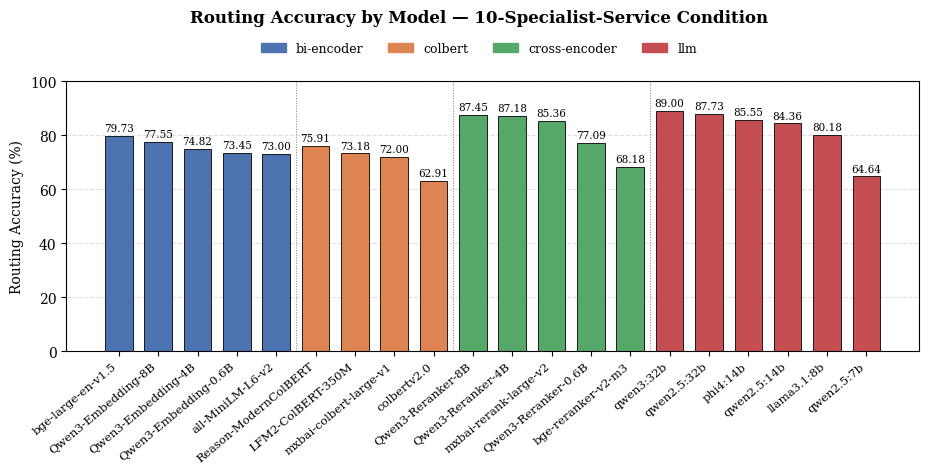

In [6]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

rq1_accuracy["short_name"] = rq1_accuracy["model_name"].str.split("/").str[-1]

approach_order = ["bi-encoder", "colbert", "cross-encoder", "llm"]
rq1_accuracy["routing_method"] = pd.Categorical(
    rq1_accuracy["routing_method"], categories=approach_order, ordered=True
)
rq1_accuracy = rq1_accuracy.sort_values(
    ["routing_method", "accuracy_percent"], ascending=[True, False]
).reset_index(drop=True)

mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
})

colors = {
    "bi-encoder": "#4C72B0",
    "colbert": "#DD8452",
    "cross-encoder": "#55A868",
    "llm": "#C44E52",
}
bar_colors = rq1_accuracy["routing_method"].map(colors)

fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(len(rq1_accuracy))
ax.bar(x, rq1_accuracy["accuracy_percent"], color=bar_colors,
       edgecolor="black", linewidth=0.6, width=0.7)

for xi, v in zip(x, rq1_accuracy["accuracy_percent"]):
    ax.text(xi, v + 1, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(rq1_accuracy["short_name"], rotation=40, ha="right", fontsize=8.5)
ax.set_ylabel("Routing Accuracy (%)")
ax.set_ylim(0, 100)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.suptitle("Routing Accuracy by Model — 10-Specialist-Service Condition",
             fontsize=12, weight="bold", y=1.06)

group_sizes = rq1_accuracy["routing_method"].value_counts().reindex(approach_order)
boundaries = np.cumsum(group_sizes)[:-1] - 0.5
for b in boundaries:
    ax.axvline(b, color="gray", linewidth=0.7, linestyle=":")

handles = [plt.Rectangle((0, 0), 1, 1, color=colors[k]) for k in approach_order]
fig.legend(handles, approach_order, loc="upper center", bbox_to_anchor=(0.5, 1.0),
           ncol=4, frameon=False, fontsize=9)

plt.subplots_adjust(top=0.86)

plt.savefig("rq1_accuracy_barplot.pdf", bbox_inches="tight")
plt.show()

# RQ1: Service-Level Routing Performance

In [7]:
from sklearn.metrics import precision_recall_fscore_support

service_results = []
service_order = expected_labels

for (method, model), group in rq1_df.groupby(
    ["routing_method", "model_name"]
):

    precision, recall, f1, support = precision_recall_fscore_support(
        group["expected_service"],
        group["predicted_label"],
        labels=service_order,
        zero_division=0
    )

    for service, p, r, f, n in zip(
        service_order,
        precision,
        recall,
        f1,
        support
    ):

        service_results.append({
            "Architecture": method,
            "Model": model,
            "Service": service,
            "Precision (%)": p * 100,
            "Recall (%)": r * 100,
            "F1 (%)": f * 100,
            "N": n
        })

service_metrics = pd.DataFrame(service_results)

In [8]:
print("Correct geography predictions:", geo["is_correct"].sum())
print("Total geography queries:", len(geo))

NameError: name 'geo' is not defined

In [11]:
f1_heatmap = service_metrics.pivot(
    index="Model",
    columns="Service",
    values="F1 (%)"
)

f1_heatmap

Service,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,formal_logic,general,high_school_chemistry,high_school_geography,jurisprudence,world_religions
Model,,,,,,,,,,,
BAAI/bge-large-en-v1.5,81.818182,90.000000,89.719626,79.802956,76.381910,85.446009,27.642276,91.370558,64.948454,83.417085,84.259259
BAAI/bge-reranker-v2-m3,69.565217,84.507042,73.003802,72.189349,62.637363,79.487179,24.324324,72.549020,47.552448,68.965517,72.500000
LiquidAI/LFM2-ColBERT-350M,89.756098,87.000000,89.423077,74.736842,57.142857,65.068493,49.769585,91.282051,53.892216,69.565217,74.871795
Qwen/Qwen3-Embedding-0.6B,94.300518,84.615385,89.898990,57.142857,81.000000,85.972851,46.000000,87.777778,0.000000,75.454545,76.635514
Qwen/Qwen3-Embedding-4B,88.524590,88.785047,88.679245,64.864865,70.270270,91.542289,51.908397,74.534161,19.642857,80.172414,83.333333
Qwen/Qwen3-Embedding-8B,86.363636,92.307692,90.721649,63.013699,86.238532,86.124402,51.963746,84.571429,42.519685,84.729064,84.507042
Qwen/Qwen3-Reranker-0.6B,89.719626,84.716157,82.727273,64.102564,85.581395,89.400922,42.352941,91.866029,60.240964,74.261603,65.868263
Qwen/Qwen3-Reranker-4B,91.707317,92.018779,94.634146,85.106383,93.750000,89.400922,69.000000,97.512438,67.532468,86.407767,86.757991
Qwen/Qwen3-Reranker-8B,95.477387,94.285714,96.907216,84.782609,93.877551,94.736842,65.641026,95.652174,72.727273,85.576923,79.828326


In [12]:
service_stats = pd.DataFrame({
    "min_f1": f1_heatmap.min(axis=0),
    "max_f1": f1_heatmap.max(axis=0),
    "mean_f1": f1_heatmap.mean(axis=0)
})
service_stats = service_stats.sort_values("mean_f1")

service_stats.round(2)

,min_f1,max_f1,mean_f1
Service,,,
general,24.32,69.00,47.63
high_school_geography,0.00,76.57,55.69
business_ethics,57.14,86.01,73.93
college_computer_science,45.07,95.34,76.47
jurisprudence,57.87,86.57,78.28
world_religions,65.87,91.09,80.02
formal_logic,62.42,94.74,84.53
abstract_algebra,69.57,97.51,87.67
astronomy,67.55,96.91,88.35


In [13]:
# latex_code = service_stats.to_latex(
#     caption="Service-level F1 (\\%) summary statistics across all 20 evaluated models, ordered from hardest to easiest by mean F1.",
#     label="tab:service_f1_stats",
#     column_format="lrrr",
#     header=["Mean F1 (\\%)", "Min F1 (\\%)", "Max F1 (\\%)"],
#     index_names=False,
#     escape=False,  # allows the \% in headers to render, since escape=True would double-escape them
# )

# print(latex_code)

In [14]:
method_order = ["bi-encoder", "colbert", "cross-encoder", "llm"]

ordered_models = (
    rq1_accuracy
    .assign(routing_method=pd.Categorical(rq1_accuracy["routing_method"], categories=method_order, ordered=True))
    .sort_values(["routing_method", "accuracy_percent"], ascending=[True, False])
    ["model_name"].tolist()
)
f1_heatmap = f1_heatmap.loc[ordered_models]

col_order = f1_heatmap.mean(axis=0).sort_values().index.tolist()
f1_heatmap = f1_heatmap[col_order]

f1_heatmap.index = [m.split("/")[-1] if "/" in m else m for m in f1_heatmap.index]

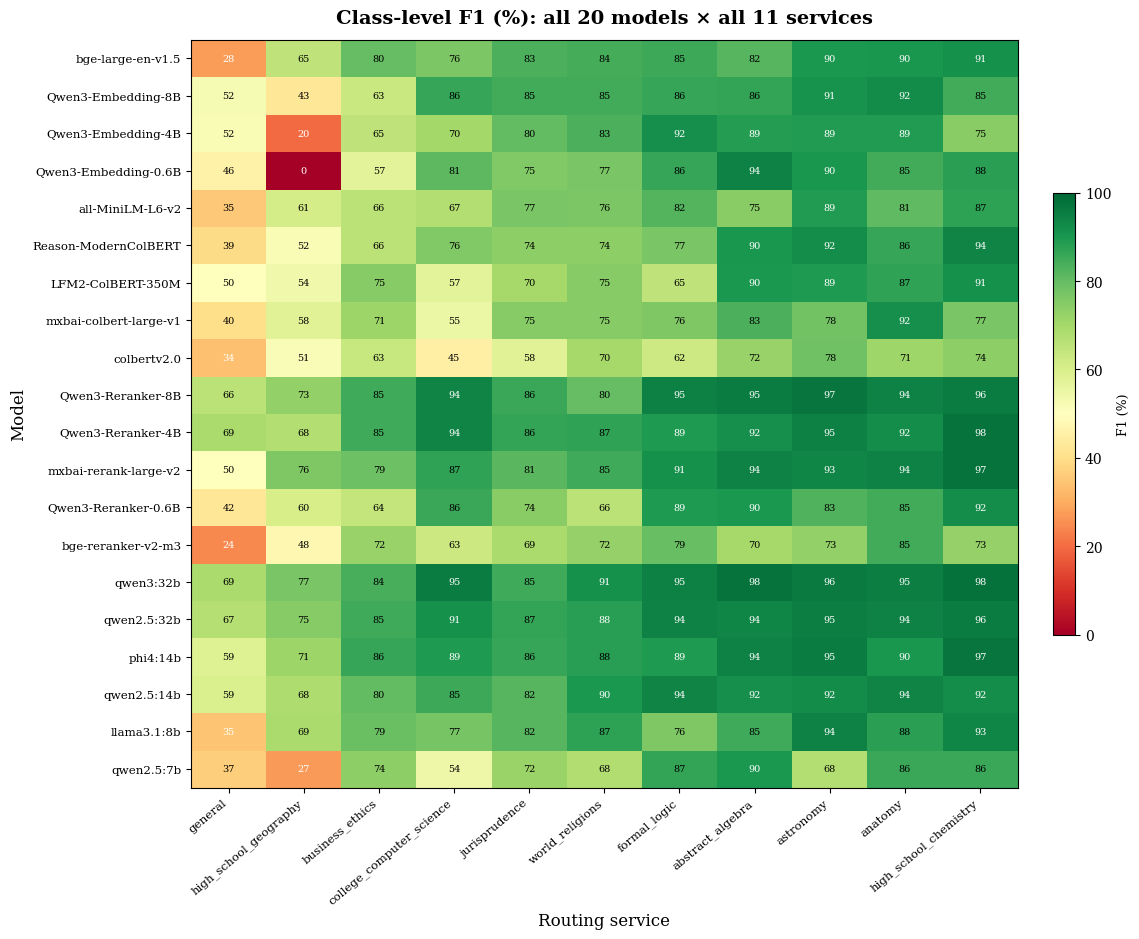

In [20]:
fig, ax = plt.subplots(figsize=(11.5, 9.5))
im = ax.imshow(f1_heatmap.values, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(f1_heatmap.columns)))
ax.set_xticklabels(f1_heatmap.columns, rotation=40, ha="right", fontsize=8.5)
ax.set_yticks(range(len(f1_heatmap.index)))
ax.set_yticklabels(f1_heatmap.index, fontsize=8.5)

for i in range(f1_heatmap.shape[0]):
    for j in range(f1_heatmap.shape[1]):
        val = f1_heatmap.values[i, j]
        color = "white" if val < 35 or val > 88 else "black"
        ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=7, color=color)

ax.set_title("Class-level F1 (%): all 20 models × all 11 services", fontsize=14, weight="bold", pad=12)
cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.04)
cbar.set_label("F1 (%)", fontsize=9)

ax.set_xlabel("Routing service",fontsize=12)
ax.set_ylabel("Model",fontsize=12)

plt.tight_layout()
plt.savefig("class_f1_heatmap.pdf", bbox_inches="tight")
plt.show()

In [11]:
# # Macro F1 per model — using expected_labels so UNMATCHED is excluded

# from sklearn.metrics import f1_score

# macro_f1_results = []

# for (method, model), group in rq1_df.groupby(
#     ["routing_method", "model_name"]
# ):

#     macro_f1 = f1_score(
#         group["expected_service"],
#         group["predicted_label"],
#         labels=expected_labels,
#         average="macro",
#         zero_division=0
#     )

#     macro_f1_results.append({
#         "routing_method": method,
#         "model_name": model,
#         "macro_f1": macro_f1
#     })

# rq1_f1 = pd.DataFrame(macro_f1_results)

# rq1_f1["macro_f1_percent"] = (
#     rq1_f1["macro_f1"] * 100
# )

# rq1_f1

In [12]:
# # Merge into one summary table


# rq1_summary = rq1_accuracy.merge(
#     rq1_f1,
#     on=["routing_method", "model_name"],
#     how="inner",
#     validate="one_to_one"
# )
# rq1_summary = rq1_summary[
#     ["routing_method", "model_name", "accuracy_percent", "macro_f1_percent"]
# ].sort_values("accuracy_percent", ascending=False)

# rq1_summary.round(2)

In [ ]:
# Investigate 

# geo = rq1_df[
#     (rq1_df["model_name"] == "Qwen/Qwen3-Embedding-0.6B") &
#     (rq1_df["expected_service"] == "high_school_geography")
# ]

# geo["predicted_label"].value_counts()

# # service_metrics[
# #     (service_metrics["Model"] == "Qwen/Qwen3-Embedding-0.6B") &
# #     (service_metrics["Service"] == "high_school_geography")
# # ][["Precision (%)", "Recall (%)", "F1 (%)", "N"]]

In [17]:
geography_errors = rq1_df[
    (rq1_df["expected_service"] == "high_school_geography")
    &
    (rq1_df["predicted_label"] != "high_school_geography")
].copy()

In [18]:
geography_confusions = (
    geography_errors
    .groupby("predicted_label")
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

geography_confusions

,predicted_label,count
7,general,435
10,world_religions,295
4,business_ethics,82
9,jurisprudence,67
3,astronomy,48
1,abstract_algebra,39
2,anatomy,39
6,formal_logic,27
8,high_school_chemistry,16
5,college_computer_science,15


In [19]:
rq1_df

,routing_method,query,raw_response,predicted_label,model_name,latency_ms,prompt_tokens,completion_tokens,total_tokens,query_id,expected_service,is_correct,error,specialist_service_count,total_service_count
0,bi-encoder,Statement 1 | If a group has an element of ord...,NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,377.911569,65,0,65,0,abstract_algebra,True,NaN,10,11
1,bi-encoder,"Statement 1 | If G, H and K are groups of orde...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,98.242861,58,0,58,1,abstract_algebra,True,NaN,10,11
2,bi-encoder,"(Z,*) is a group with a*b = a+b+1 for all a, b...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,87.710913,28,0,28,2,abstract_algebra,True,NaN,10,11
3,bi-encoder,"Statement 1 | For any two groups G and G', the...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,55.024976,39,0,39,3,abstract_algebra,True,NaN,10,11
4,bi-encoder,"Let A and B be sets, f: A -> B and g: B -> A b...",NaN,formal_logic,Qwen/Qwen3-Embedding-8B,38.079356,63,0,63,4,abstract_algebra,False,NaN,10,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21995,llm,Allen's (2001) study of nurses showed that:,jurisprudence,jurisprudence,llama3.1:8b,304.938247,867,5,872,1095,general,False,NaN,10,11
21996,llm,The term 'secondary deviation' refers to:,formal_logic,formal_logic,llama3.1:8b,300.741887,864,4,868,1096,general,False,NaN,10,11
21997,llm,Murray thought that the 'underclass' consisted...,service general,general,llama3.1:8b,424.749427,869,3,872,1097,general,True,NaN,10,11
21998,llm,"According to Foucault, carceral organizations:",jurisprudence,jurisprudence,llama3.1:8b,466.334821,865,5,870,1098,general,False,NaN,10,11


In [20]:
general_errors = rq1_df[
    (rq1_df["expected_service"] == "general")
    &
    (rq1_df["predicted_label"] != "general")
].copy()

print("Total general errors:", len(general_errors))

general_confusions = (
    general_errors
    .groupby("predicted_label")
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

general_confusions["percent_of_errors"] = (
    general_confusions["error_count"]
    / len(general_errors)
    * 100
)

general_confusions.round(2)

Total general errors: 948


,predicted_label,error_count,percent_of_errors
1,anatomy,176,18.57
9,world_religions,154,16.24
7,high_school_geography,143,15.08
8,jurisprudence,125,13.19
3,business_ethics,97,10.23
2,astronomy,69,7.28
4,college_computer_science,66,6.96
5,formal_logic,60,6.33
0,abstract_algebra,38,4.01
6,high_school_chemistry,20,2.11


In [23]:
# unmatched

rq1_df["is_unmatched"] = ~rq1_df["predicted_label"].isin(expected_labels)

unmatched_summary = (
    rq1_df
    .groupby(["routing_method", "model_name"])
    .agg(
        total_queries=("predicted_label", "size"),
        unmatched=("is_unmatched", "sum")
    )
    .reset_index()
)

unmatched_summary["unmatched_rate_percent"] = (
    unmatched_summary["unmatched"]
    / unmatched_summary["total_queries"]
    * 100
)

unmatched_summary

,routing_method,model_name,total_queries,unmatched,unmatched_rate_percent
0,bi-encoder,BAAI/bge-large-en-v1.5,1100,0,0.000000
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,1100,0,0.000000
2,bi-encoder,Qwen/Qwen3-Embedding-4B,1100,0,0.000000
3,bi-encoder,Qwen/Qwen3-Embedding-8B,1100,0,0.000000
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,1100,0,0.000000
5,colbert,LiquidAI/LFM2-ColBERT-350M,1100,0,0.000000
6,colbert,colbert-ir/colbertv2.0,1100,0,0.000000
7,colbert,lightonai/Reason-ModernColBERT,1100,0,0.000000
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,1100,0,0.000000
9,cross-encoder,BAAI/bge-reranker-v2-m3,1100,0,0.000000


In [26]:
unmatched_cases = rq1_df[
    rq1_df["is_unmatched"]
][
    [
        "routing_method",
        "model_name",
        "expected_service",
        "raw_response",
        "predicted_label",

    ]
]

unmatched_cases

,routing_method,model_name,expected_service,raw_response,predicted_label
3739,llm,qwen2.5:14b,college_computer_science,high_school_computer_science,UNMATCHED
12268,llm,phi4:14b,anatomy,None of the services listed directly address a...,UNMATCHED
12663,llm,phi4:14b,formal_logic,None of the listed services directly match or ...,UNMATCHED
17877,llm,qwen2.5:7b,astronomy,aerospace_engineering,UNMATCHED
21144,llm,llama3.1:8b,astronomy,aerospace_engineering,UNMATCHED
21612,llm,llama3.1:8b,high_school_geography,service demography,UNMATCHED
21688,llm,llama3.1:8b,high_school_geography,service economics_not_listed,UNMATCHED
